# 05. IPCA: Blocos Macroeconômicos

## Parte 0 · De Onde Economicamente Está Vindo a Inflação?

Os notebooks anteriores responderam:

- 02.ipca → Quanto foi a inflação?
- 02.01 → 02.04 → Onde ocorreram os movimentos?
- 03.ipca_decomposicao → A decomposição é consistente?
- 04.ipca_dinamica_inflacionaria → Qual é a natureza do processo inflacionário?

Neste notebook mudamos novamente a pergunta:

> De onde economicamente está vindo a inflação?

O objetivo agora não é estudar a dinâmica estatística da inflação,
mas sim interpretar suas fontes econômicas.

Utilizamos duas taxonomias:

Taxonomia Econômica

- ALIMENTACAO_DOMICILIO
- ALIMENTACAO_FORA
- BENS_INDUSTRIAIS
- SERVICOS
- MONITORADOS

Taxonomia Cidadã

- MERCADO
- ALIMENTACAO_FORA
- MORADIA
- TRANSPORTE
- SAUDE
- EDUCACAO
- COMUNICACAO
- LAZER
- CASA
- VESTUARIO
- SERVICOS_PESSOAIS

Assim passamos a responder:

> Como a inflação se distribui economicamente?

e:

> O que está pressionando o orçamento das famílias?

### Objetivos

1. Validar a cobertura da taxonomia.
2. Reconstruir o IPCA pelos blocos.
3. Medir a contribuição dos blocos macroeconômicos.
4. Medir a participação relativa dos blocos.
5. Analisar a composição histórica do IPCA.
6. Construir uma leitura econômica.
7. Construir uma leitura cidadã.
8. Identificar os principais vetores inflacionários.
9. Criar uma ponte entre economia e comunicação pública.

### Estrutura Analítica

IPCA
 │
 ├─────────────── Estrutura ───────────────┐
 │                                         │
 ▼                                         ▼

IBGE                                Taxonomias do Projeto

Grupo                              Econômica
Subgrupo                           • Serviços
Item                               • Alimentação
Subitem                            • Monitorados
                                   • Bens Industriais

                                   Cidadã
                                   • Mercado
                                   • Moradia
                                   • Transporte
                                   • Saúde
                                   • Educação

                                            │
                                            ▼

                        De onde vem a inflação?

                        • Para o economista
                        • Para o cidadão

### 1. Configuração do Ambiente

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /home/moacir/projects/ml/analytics/inflation


### 2. Importações

In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.patches import Patch
from matplotlib.lines import Line2D

from src.database.connection import engine

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.4f}".format)

---
## PARTE I · DADOS
---

### 3. Carregar Taxonomia

In [3]:
taxonomia = pd.read_sql(
    """
    SELECT *
    FROM bcb.vw_ipca_taxonomia
    ORDER BY subitem_id;
    """,
    engine,
)

taxonomia.head()

,grupo_id,grupo_nome,subgrupo_id,subgrupo_nome,item_id,item_nome,subitem_id,subitem_nome,bloco_macro,sub_bloco,categoria_cidada,subcategoria_cidada
0,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101002,Arroz,ALIMENTACAO_DOMICILIO,None,MERCADO,None
1,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101051,Feijão - mulatinho,ALIMENTACAO_DOMICILIO,None,MERCADO,None
2,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101052,Feijão - preto,ALIMENTACAO_DOMICILIO,None,MERCADO,None
3,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101053,Feijão - macáçar (fradinho),ALIMENTACAO_DOMICILIO,None,MERCADO,None
4,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101073,Feijão - carioca (rajado),ALIMENTACAO_DOMICILIO,None,MERCADO,None


### 4. Carregar Subitens

In [4]:
subitens = pd.read_sql(
    """
    SELECT
        date,
        categoria,
        categoria_nome,
        indice,
        peso
    FROM bcb.ipca_subitens
    ORDER BY date, categoria;
    """,
    engine,
)

subitens["date"] = pd.to_datetime(
    subitens["date"]
)

subitens["categoria"] = (
    subitens["categoria"]
    .astype(str)
)

subitens.head()

,date,categoria,categoria_nome,indice,peso
0,2020-01-01,1101002,Arroz,1.3100,0.4753
1,2020-01-01,1101051,Feijão - mulatinho,4.5000,0.0116
2,2020-01-01,1101052,Feijão - preto,-2.6800,0.0486
3,2020-01-01,1101053,Feijão - macáçar (fradinho),5.3900,0.0121
4,2020-01-01,1101073,Feijão - carioca (rajado),-0.7000,0.1350


### 5. Integrar Dados e Taxonomia

In [5]:
dados = (
    subitens
    .merge(
        taxonomia[
            [
                "subitem_id",
                "bloco_macro",
                "categoria_cidada",
            ]
        ],
        left_on="categoria",
        right_on="subitem_id",
        how="left",
    )
)

dados["contribuicao"] = (
    dados["indice"]
    * dados["peso"]
    / 100
)

dados["impacto"] = (
    dados["contribuicao"]
    .abs()
)

dados.head()

,date,categoria,categoria_nome,indice,peso,subitem_id,bloco_macro,categoria_cidada,contribuicao,impacto
0,2020-01-01,1101002,Arroz,1.3100,0.4753,1101002,ALIMENTACAO_DOMICILIO,MERCADO,0.0062,0.0062
1,2020-01-01,1101051,Feijão - mulatinho,4.5000,0.0116,1101051,ALIMENTACAO_DOMICILIO,MERCADO,0.0005,0.0005
2,2020-01-01,1101052,Feijão - preto,-2.6800,0.0486,1101052,ALIMENTACAO_DOMICILIO,MERCADO,-0.0013,0.0013
3,2020-01-01,1101053,Feijão - macáçar (fradinho),5.3900,0.0121,1101053,ALIMENTACAO_DOMICILIO,MERCADO,0.0007,0.0007
4,2020-01-01,1101073,Feijão - carioca (rajado),-0.7000,0.1350,1101073,ALIMENTACAO_DOMICILIO,MERCADO,-0.0009,0.0009


### 6. Cobertura da Taxonomia

In [6]:
cobertura = (
    dados[
        [
            "categoria",
            "bloco_macro",
            "categoria_cidada",
        ]
    ]
    .drop_duplicates()
)

pd.DataFrame(
    {
        "indicador": [
            "subitens",
            "blocos_macro",
            "categorias_cidadas",
        ],
        "valor": [
            cobertura["categoria"].nunique(),
            cobertura["bloco_macro"].nunique(),
            cobertura["categoria_cidada"].nunique(),
        ],
    }
)

,indicador,valor
0,subitens,377
1,blocos_macro,5
2,categorias_cidadas,11


In [7]:
na_taxonomia = (
    dados[
        dados["bloco_macro"].isna()
    ]
)

na_taxonomia

,date,categoria,categoria_nome,indice,peso,subitem_id,bloco_macro,categoria_cidada,contribuicao,impacto


### 7. Estatísticas Gerais

In [8]:
pd.DataFrame(
    [
        {
            "indicador": "Observações",
            "valor": len(dados),
        },
        {
            "indicador": "Subitens",
            "valor": dados["categoria"].nunique(),
        },
        {
            "indicador": "Início",
            "valor": dados["date"].min(),
        },
        {
            "indicador": "Fim",
            "valor": dados["date"].max(),
        },
    ]
)

,indicador,valor
0,Observações,30160
1,Subitens,377
2,Início,2020-01-01 00:00:00
3,Fim,2026-08-01 00:00:00


---
## PARTE II · BLOCOS MACROECONÔMICOS
---

Agora abandonamos a visão por subitem
e passamos a estudar:

ALIMENTACAO_DOMICILIO
ALIMENTACAO_FORA
BENS_INDUSTRIAIS
SERVICOS
MONITORADOS

A pergunta passa a ser:

> Qual bloco econômico está por trás da inflação?

### 8. Construir Blocos Macroeconômicos

In [9]:
blocos = (
    dados
    .groupby(
        [
            "date",
            "bloco_macro",
        ]
    )
    .agg(
        contribuicao=(
            "contribuicao",
            "sum",
        ),
        impacto=(
            "impacto",
            "sum",
        ),
    )
    .reset_index()
)

blocos.tail()

,date,bloco_macro,contribuicao,impacto
395,2026-08-01,ALIMENTACAO_DOMICILIO,-0.0941,0.2842
396,2026-08-01,ALIMENTACAO_FORA,0.0219,0.0219
397,2026-08-01,BENS_INDUSTRIAIS,0.1278,0.2471
398,2026-08-01,MONITORADOS,-0.3627,0.4102
399,2026-08-01,SERVICOS,-0.0104,0.2630


### 9. Matriz Temporal

In [10]:
blocos_pivot = (
    blocos
    .pivot(
        index="date",
        columns="bloco_macro",
        values="contribuicao",
    )
    .sort_index()
)

blocos_pivot.tail()

bloco_macro,ALIMENTACAO_DOMICILIO,ALIMENTACAO_FORA,BENS_INDUSTRIAIS,MONITORADOS,SERVICOS
date,,,,,
2026-04-01,0.2524,0.0357,0.1944,0.1963,-0.0127
2026-05-01,0.2570,0.0297,0.1274,0.0557,0.1149
2026-06-01,-0.0609,0.0093,0.0394,0.0577,0.1139
2026-07-01,-0.1774,0.0331,-0.0053,0.0493,0.1662
2026-08-01,-0.0941,0.0219,0.1278,-0.3627,-0.0104


### 10. Reconstrução do IPCA pelos Blocos

Se a taxonomia estiver correta:

ALIMENTAÇÃO
+
SERVIÇOS
+
MONITORADOS
+
BENS

=

IPCA

In [11]:
ipca = pd.read_sql(
    """
    SELECT
        date,
        indice,
        acumulado12m
    FROM bcb.ipca_geral
    ORDER BY date;
    """,
    engine,
)

ipca["date"] = pd.to_datetime(
    ipca["date"]
)

ipca.head()

,date,indice,acumulado12m
0,1979-12-01,NaN,NaN
1,1980-01-01,6.6200,NaN
2,1980-02-01,4.6200,NaN
3,1980-03-01,6.0400,NaN
4,1980-04-01,5.2900,NaN


In [12]:
reconstrucao = (
    blocos_pivot
    .sum(axis=1)
    .rename("ipca_blocos")
    .reset_index()
)

reconstrucao.head()

,date,ipca_blocos
0,2020-01-01,0.2129
1,2020-02-01,0.2461
2,2020-03-01,0.0651
3,2020-04-01,-0.3080
4,2020-05-01,-0.3762


In [13]:
validacao = (
    ipca
    .merge(
        reconstrucao,
        on="date",
    )
)

validacao["erro"] = (
    validacao["ipca_blocos"]
    - validacao["indice"]
)

validacao["erro_abs"] = (
    validacao["erro"]
    .abs()
)

validacao.tail()

,date,indice,acumulado12m,ipca_blocos,erro,erro_abs
75,2026-04-01,0.6700,4.3900,0.6661,-0.0039,0.0039
76,2026-05-01,0.5800,4.7200,0.5847,0.0047,0.0047
77,2026-06-01,0.1600,4.6400,0.1595,-0.0005,0.0005
78,2026-07-01,0.0700,4.4400,0.0658,-0.0042,0.0042
79,2026-08-01,-0.3200,4.2200,-0.3176,0.0024,0.0024


### 11. Erro de Reconstrução

In [14]:
validacao[
    [
        "erro",
        "erro_abs",
    ]
].describe()

,erro,erro_abs
count,80.0000,80.0000
mean,-0.0005,0.0027
std,0.0031,0.0015
min,-0.0052,0.0000
25%,-0.0032,0.0014
50%,-0.0009,0.0029
75%,0.0020,0.0041
max,0.0048,0.0052


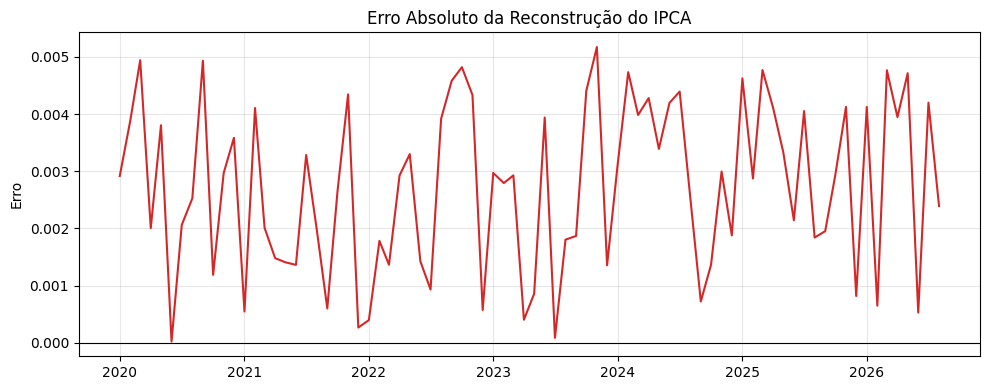

In [15]:
plt.figure(figsize=(10,4))

plt.plot(
    validacao["date"],
    validacao["erro_abs"],
    color="tab:red",
)

plt.axhline(
    0,
    color="black",
    linewidth=0.8,
)

plt.title(
    "Erro Absoluto da Reconstrução do IPCA"
)

plt.ylabel("Erro")

plt.grid(
    alpha=0.3,
)

plt.tight_layout()
plt.show()

### 12. Evolução Histórica dos Blocos

In [16]:
blocos_10a = (
    blocos_pivot[
        blocos_pivot.index
        >= (
            blocos_pivot.index.max()
            - pd.DateOffset(years=10)
        )
    ]
)

blocos_10a.tail()

bloco_macro,ALIMENTACAO_DOMICILIO,ALIMENTACAO_FORA,BENS_INDUSTRIAIS,MONITORADOS,SERVICOS
date,,,,,
2026-04-01,0.2524,0.0357,0.1944,0.1963,-0.0127
2026-05-01,0.2570,0.0297,0.1274,0.0557,0.1149
2026-06-01,-0.0609,0.0093,0.0394,0.0577,0.1139
2026-07-01,-0.1774,0.0331,-0.0053,0.0493,0.1662
2026-08-01,-0.0941,0.0219,0.1278,-0.3627,-0.0104


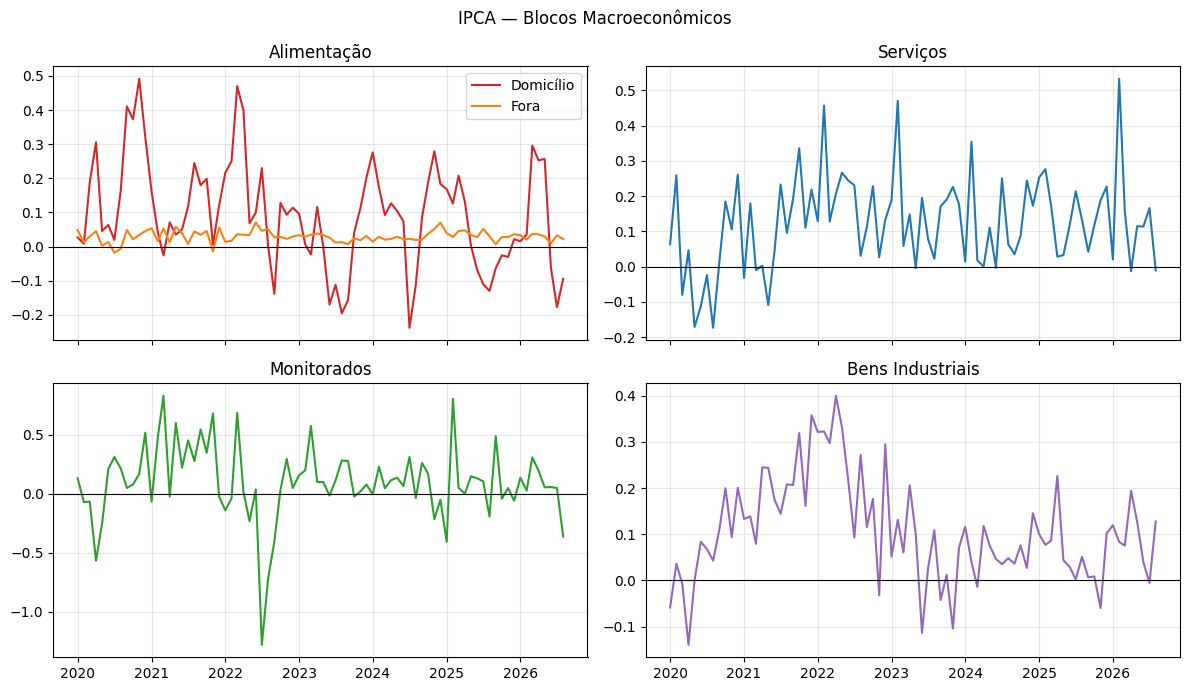

In [17]:
fig, ax = plt.subplots(
    2,
    2,
    figsize=(12, 7),
    sharex=True,
)

# ==================================================
# ALIMENTAÇÃO
# ==================================================

ax[0,0].plot(
    blocos_10a.index,
    blocos_10a["ALIMENTACAO_DOMICILIO"],
    label="Domicílio",
    color="tab:red",
)

ax[0,0].plot(
    blocos_10a.index,
    blocos_10a["ALIMENTACAO_FORA"],
    label="Fora",
    color="tab:orange",
)

ax[0,0].set_title(
    "Alimentação"
)

ax[0,0].legend()

# ==================================================
# SERVIÇOS
# ==================================================

ax[0,1].plot(
    blocos_10a.index,
    blocos_10a["SERVICOS"],
    color="tab:blue",
)

ax[0,1].set_title(
    "Serviços"
)

# ==================================================
# MONITORADOS
# ==================================================

ax[1,0].plot(
    blocos_10a.index,
    blocos_10a["MONITORADOS"],
    color="tab:green",
)

ax[1,0].set_title(
    "Monitorados"
)

# ==================================================
# BENS
# ==================================================

ax[1,1].plot(
    blocos_10a.index,
    blocos_10a["BENS_INDUSTRIAIS"],
    color="tab:purple",
)

ax[1,1].set_title(
    "Bens Industriais"
)

# ==================================================

for eixo in ax.flat:

    eixo.axhline(
        0,
        color="black",
        linewidth=0.8,
    )

    eixo.grid(
        alpha=0.3,
    )

plt.suptitle(
    "IPCA — Blocos Macroeconômicos"
)

plt.tight_layout()

plt.show()

### 13. Participação Relativa dos Blocos

In [18]:
impacto_total = (
    blocos
    .groupby("date")
    ["impacto"]
    .sum()
)

blocos = (
    blocos
    .merge(
        impacto_total.rename(
            "impacto_total"
        ),
        on="date",
    )
)

blocos["participacao"] = (
    blocos["impacto"]
    / blocos["impacto_total"]
)

blocos.tail()

,date,bloco_macro,contribuicao,impacto,impacto_total,participacao
395,2026-08-01,ALIMENTACAO_DOMICILIO,-0.0941,0.2842,1.2264,0.2318
396,2026-08-01,ALIMENTACAO_FORA,0.0219,0.0219,1.2264,0.0178
397,2026-08-01,BENS_INDUSTRIAIS,0.1278,0.2471,1.2264,0.2015
398,2026-08-01,MONITORADOS,-0.3627,0.4102,1.2264,0.3345
399,2026-08-01,SERVICOS,-0.0104,0.2630,1.2264,0.2144


### 14. Participação dos Blocos no Último Mês

In [19]:
ultimo_mes = (
    blocos["date"]
    .max()
)

impacto_atual = (
    blocos[
        blocos["date"]
        == ultimo_mes
    ]
    .sort_values(
        "participacao",
        ascending=False,
    )
)

impacto_atual

,date,bloco_macro,contribuicao,impacto,impacto_total,participacao
398,2026-08-01,MONITORADOS,-0.3627,0.4102,1.2264,0.3345
395,2026-08-01,ALIMENTACAO_DOMICILIO,-0.0941,0.2842,1.2264,0.2318
399,2026-08-01,SERVICOS,-0.0104,0.2630,1.2264,0.2144
397,2026-08-01,BENS_INDUSTRIAIS,0.1278,0.2471,1.2264,0.2015
396,2026-08-01,ALIMENTACAO_FORA,0.0219,0.0219,1.2264,0.0178


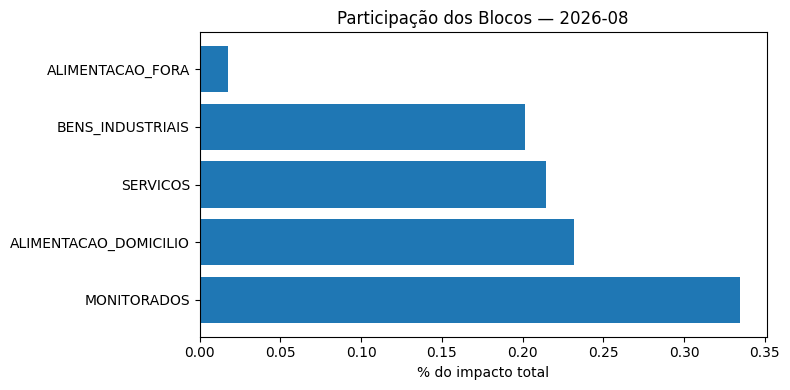

In [20]:
plt.figure(figsize=(8,4))

plt.barh(
    impacto_atual["bloco_macro"],
    impacto_atual["participacao"],
)

plt.title(
    f"Participação dos Blocos — {ultimo_mes:%Y-%m}"
)

plt.xlabel(
    "% do impacto total"
)

plt.tight_layout()
plt.show()

### 15. Ranking Econômico

In [21]:
macro_atual = (
    blocos[
        blocos["date"]
        == ultimo_mes
    ]
    .sort_values(
        "contribuicao",
        ascending=False,
    )
)

macro_atual

,date,bloco_macro,contribuicao,impacto,impacto_total,participacao
397,2026-08-01,BENS_INDUSTRIAIS,0.1278,0.2471,1.2264,0.2015
396,2026-08-01,ALIMENTACAO_FORA,0.0219,0.0219,1.2264,0.0178
399,2026-08-01,SERVICOS,-0.0104,0.2630,1.2264,0.2144
395,2026-08-01,ALIMENTACAO_DOMICILIO,-0.0941,0.2842,1.2264,0.2318
398,2026-08-01,MONITORADOS,-0.3627,0.4102,1.2264,0.3345


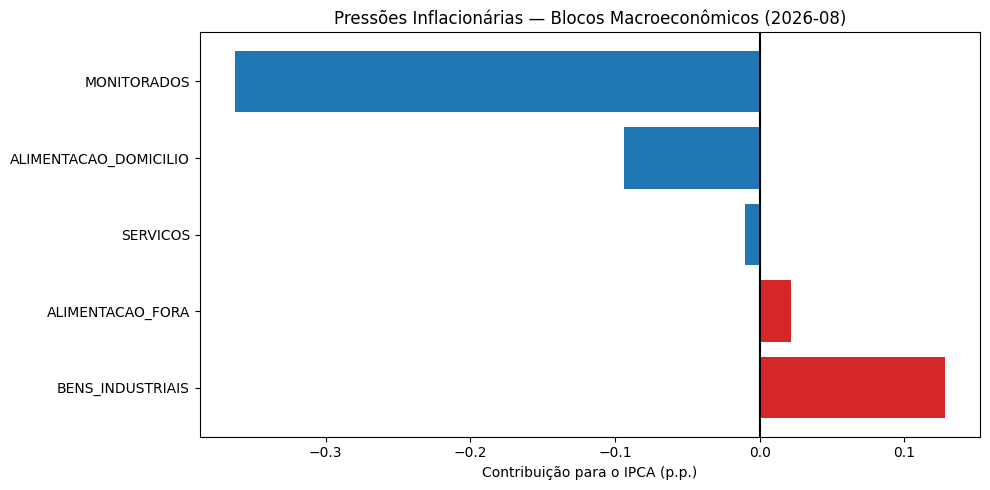

In [22]:
cores = np.where(
    macro_atual["contribuicao"] >= 0,
    "tab:red",
    "tab:blue",
)

plt.figure(figsize=(10,5))

plt.barh(
    macro_atual["bloco_macro"],
    macro_atual["contribuicao"],
    color=cores,
)

plt.axvline(
    0,
    color="black",
)

plt.title(
    f"Pressões Inflacionárias — Blocos Macroeconômicos ({ultimo_mes:%Y-%m})"
)

plt.xlabel(
    "Contribuição para o IPCA (p.p.)"
)

plt.tight_layout()
plt.show()

### 16. Contribuições Acumuladas em 12 Meses

Importante:

Esta medida representa:

soma das contribuições mensais dos últimos 12 meses.

Não representa a decomposição exata da inflação composta.

In [23]:
blocos_12m = (
    blocos_pivot
    .rolling(12)
    .sum()
)

blocos_12m.tail()

bloco_macro,ALIMENTACAO_DOMICILIO,ALIMENTACAO_FORA,BENS_INDUSTRIAIS,MONITORADOS,SERVICOS
date,,,,,
2026-04-01,0.1983,0.3705,0.6580,1.3001,1.7721
2026-05-01,0.4518,0.3658,0.7415,1.2072,1.8540
2026-06-01,0.4592,0.3475,0.7514,1.1333,1.8505
2026-07-01,0.3917,0.3287,0.7437,1.0769,1.8027
2026-08-01,0.4273,0.3202,0.8203,0.9073,1.6592


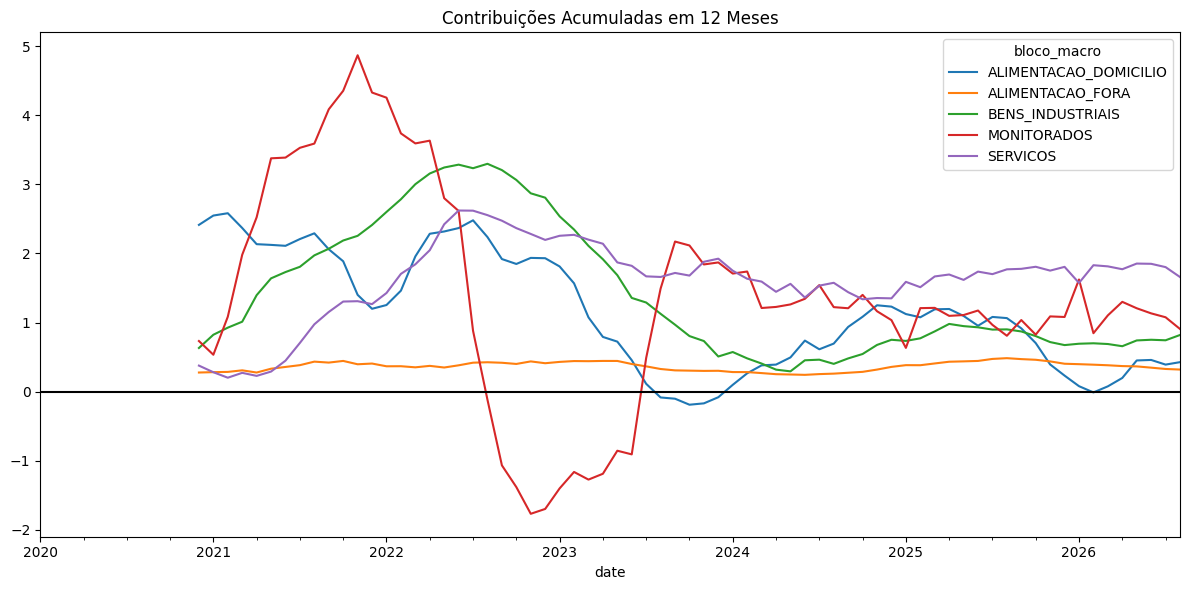

In [24]:
blocos_12m.tail(120).plot(
    figsize=(12,6)
)

plt.axhline(
    0,
    color="black",
)

plt.title(
    "Contribuições Acumuladas em 12 Meses"
)

plt.tight_layout()
plt.show()

### 17. Heatmap Econômico

In [25]:
heat_macro = (
    blocos
    .pivot(
        index="date",
        columns="bloco_macro",
        values="contribuicao",
    )
    .tail(24)
)

heat_macro.index = (
    heat_macro.index
    .strftime("%b-%y")
)

heat_macro.tail()

bloco_macro,ALIMENTACAO_DOMICILIO,ALIMENTACAO_FORA,BENS_INDUSTRIAIS,MONITORADOS,SERVICOS
date,,,,,
Apr-26,0.2524,0.0357,0.1944,0.1963,-0.0127
May-26,0.2570,0.0297,0.1274,0.0557,0.1149
Jun-26,-0.0609,0.0093,0.0394,0.0577,0.1139
Jul-26,-0.1774,0.0331,-0.0053,0.0493,0.1662
Aug-26,-0.0941,0.0219,0.1278,-0.3627,-0.0104


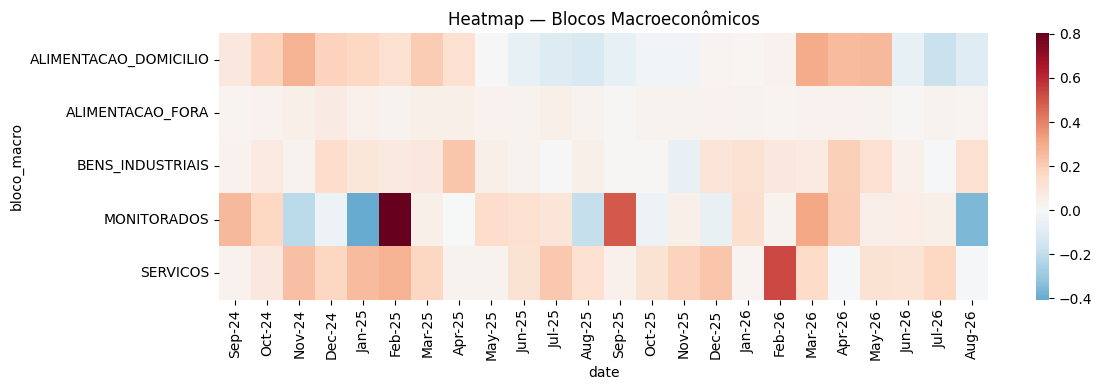

In [26]:
plt.figure(
    figsize=(12,4)
)

sns.heatmap(
    heat_macro.T,
    cmap="RdBu_r",
    center=0,
)

plt.title(
    "Heatmap — Blocos Macroeconômicos"
)

plt.tight_layout()
plt.show()



---
## PARTE III · VISÃO CIDADÃ
---

A taxonomia econômica responde:

> De onde economicamente vem a inflação?

A taxonomia cidadã responde:

> O que está pressionando o orçamento das famílias?

A ideia não é substituir a leitura macroeconômica,
mas aproximar a inflação do cotidiano.

### 18. Construir Categorias Cidadãs

In [27]:
cidada = (
    dados
    .groupby(
        [
            "date",
            "categoria_cidada",
        ]
    )
    .agg(
        contribuicao=(
            "contribuicao",
            "sum",
        ),
        impacto=(
            "impacto",
            "sum",
        ),
    )
    .reset_index()
)

cidada.tail()

,date,categoria_cidada,contribuicao,impacto
875,2026-08-01,MORADIA,-0.2899,0.3754
876,2026-08-01,SAUDE,0.0323,0.0591
877,2026-08-01,SERVICOS_PESSOAIS,0.0233,0.0245
878,2026-08-01,TRANSPORTE,-0.1731,0.2372
879,2026-08-01,VESTUARIO,0.0055,0.0253


### 19. Matriz Temporal

In [28]:
cidada_pivot = (
    cidada
    .pivot(
        index="date",
        columns="categoria_cidada",
        values="contribuicao",
    )
    .sort_index()
)

cidada_pivot.tail()

categoria_cidada,ALIMENTACAO_FORA,CASA,COMUNICACAO,EDUCACAO,LAZER,MERCADO,MORADIA,SAUDE,SERVICOS_PESSOAIS,TRANSPORTE,VESTUARIO
date,,,,,,,,,,,
2026-04-01,0.0357,0.0226,0.0259,0.0038,-0.0070,0.2524,0.0955,0.1582,0.0426,0.0121,0.0242
2026-05-01,0.0297,0.0028,0.0103,-0.0001,0.0139,0.2570,0.1862,0.1226,0.0279,-0.0945,0.0288
2026-06-01,0.0093,0.0080,0.0086,-0.0015,-0.0005,-0.0609,0.0967,0.0315,0.0262,0.0343,0.0078
2026-07-01,0.0331,0.0024,0.0020,-0.0020,-0.0001,-0.1774,0.1512,0.0555,0.0222,0.0096,-0.0307
2026-08-01,0.0219,0.0221,-0.0041,0.0292,0.1095,-0.0941,-0.2899,0.0323,0.0233,-0.1731,0.0055


### 20. Evolução Histórica

In [29]:
cidada_10a = (
    cidada_pivot[
        cidada_pivot.index
        >= (
            cidada_pivot.index.max()
            - pd.DateOffset(years=10)
        )
    ]
)

cidada_10a.tail()

categoria_cidada,ALIMENTACAO_FORA,CASA,COMUNICACAO,EDUCACAO,LAZER,MERCADO,MORADIA,SAUDE,SERVICOS_PESSOAIS,TRANSPORTE,VESTUARIO
date,,,,,,,,,,,
2026-04-01,0.0357,0.0226,0.0259,0.0038,-0.0070,0.2524,0.0955,0.1582,0.0426,0.0121,0.0242
2026-05-01,0.0297,0.0028,0.0103,-0.0001,0.0139,0.2570,0.1862,0.1226,0.0279,-0.0945,0.0288
2026-06-01,0.0093,0.0080,0.0086,-0.0015,-0.0005,-0.0609,0.0967,0.0315,0.0262,0.0343,0.0078
2026-07-01,0.0331,0.0024,0.0020,-0.0020,-0.0001,-0.1774,0.1512,0.0555,0.0222,0.0096,-0.0307
2026-08-01,0.0219,0.0221,-0.0041,0.0292,0.1095,-0.0941,-0.2899,0.0323,0.0233,-0.1731,0.0055


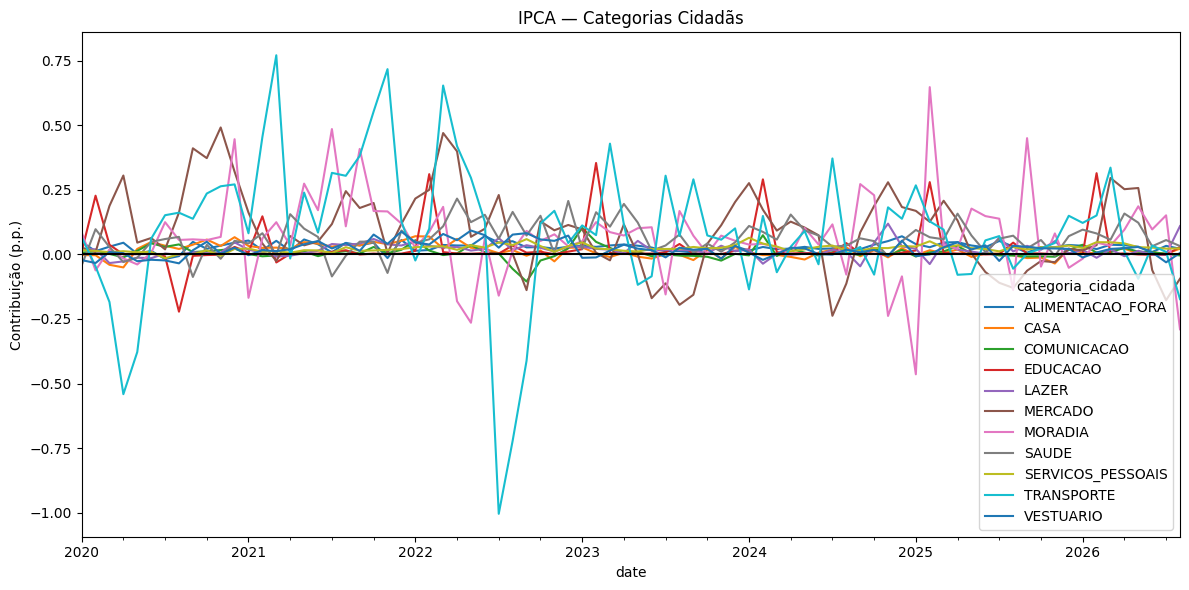

In [51]:
cidada_10a.plot(figsize=(12, 6))

plt.axhline(0, color="black", linestyle="-")
plt.title("IPCA — Categorias Cidadãs")
plt.ylabel("Contribuição (p.p.)")
plt.tight_layout()
plt.show()

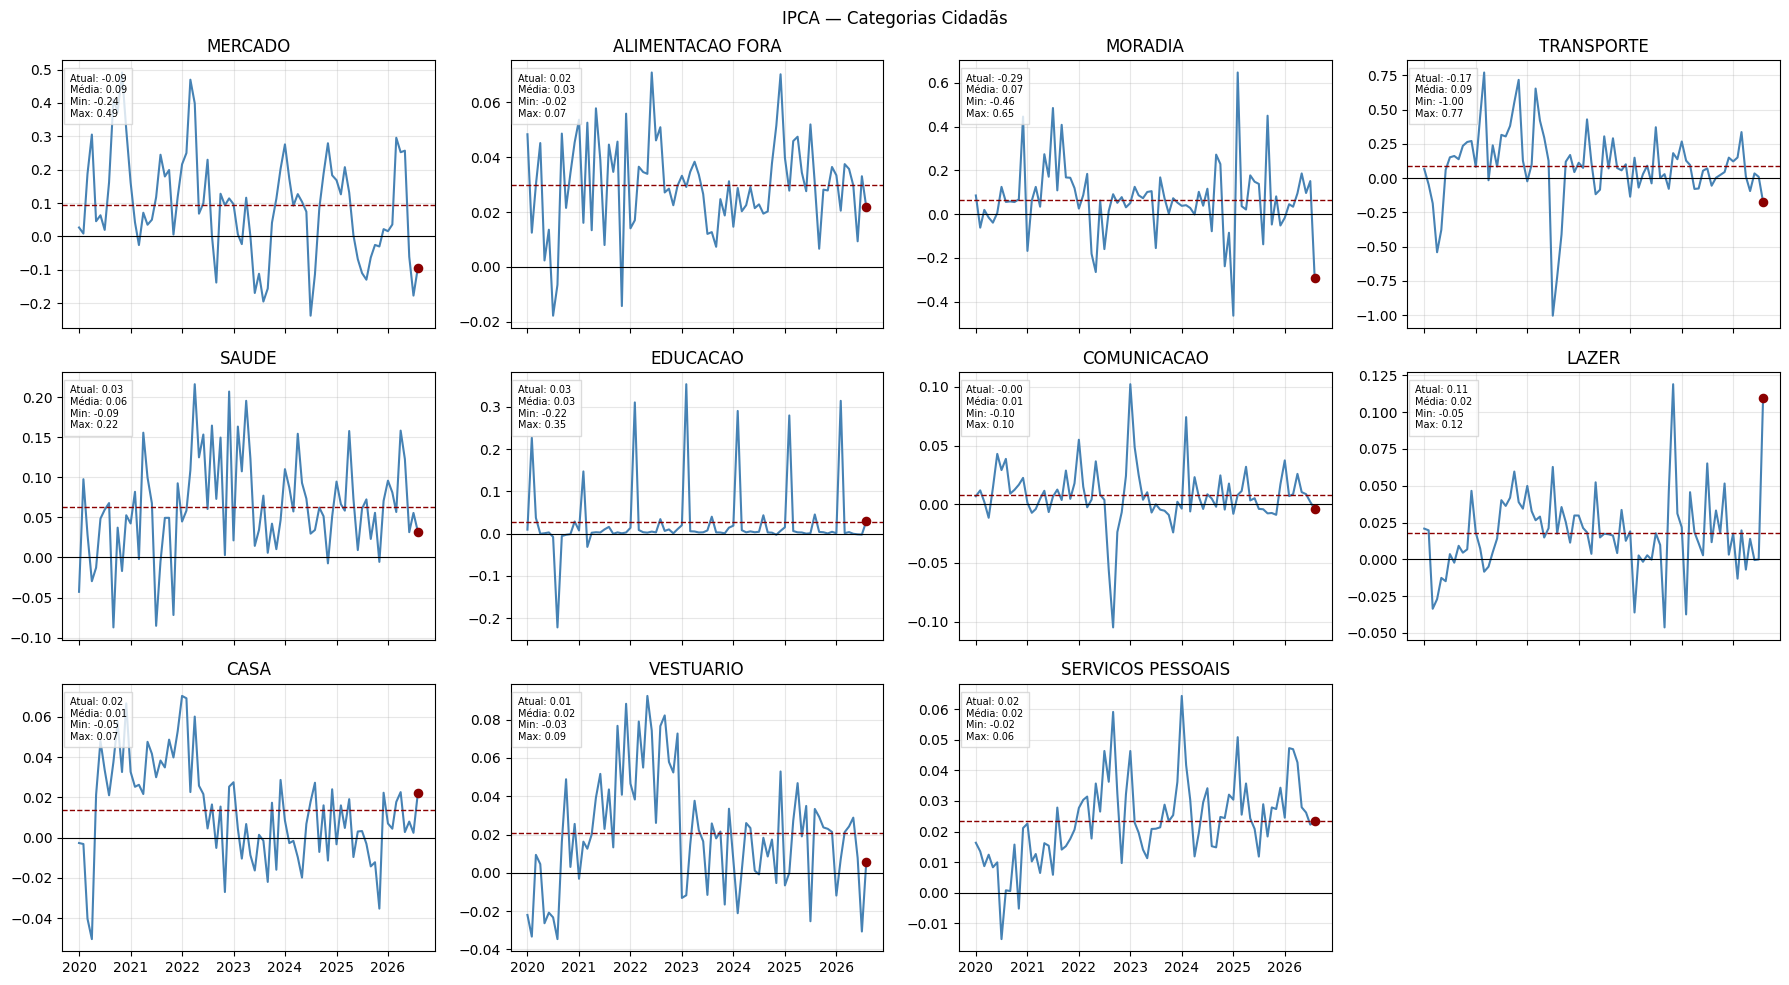

In [30]:
fig, ax = plt.subplots(
    3,
    4,
    figsize=(18, 10),
    sharex=True,
)

categorias = [
    "MERCADO",
    "ALIMENTACAO_FORA",
    "MORADIA",
    "TRANSPORTE",
    "SAUDE",
    "EDUCACAO",
    "COMUNICACAO",
    "LAZER",
    "CASA",
    "VESTUARIO",
    "SERVICOS_PESSOAIS",
]

for eixo, categoria in zip(
    ax.flat,
    categorias,
):

    if categoria not in cidada_10a.columns:
        eixo.set_visible(False)
        continue

    serie = (
        cidada_10a[categoria]
        .dropna()
    )

    media = serie.mean()
    minimo = serie.min()
    maximo = serie.max()
    atual = serie.iloc[-1]

    eixo.plot(
        serie.index,
        serie,
        color="steelblue",
        linewidth=1.5,
    )

    eixo.scatter(
        serie.index[-1],
        atual,
        color="darkred",
        s=35,
        zorder=5,
    )

    eixo.axhline(
        media,
        color="darkred",
        linestyle="--",
        linewidth=1,
        label=f"Média: {media:.2f}",
    )

    eixo.axhline(
        0,
        color="black",
        linewidth=0.8,
    )

    eixo.set_title(
        categoria.replace(
            "_",
            " "
        )
    )

    eixo.grid(
        alpha=0.3,
    )

    eixo.text(
        0.02,
        0.95,
        (
            f"Atual: {atual:.2f}\n"
            f"Média: {media:.2f}\n"
            f"Min: {minimo:.2f}\n"
            f"Max: {maximo:.2f}"
        ),
        transform=eixo.transAxes,
        fontsize=7,
        va="top",
        bbox=dict(
            facecolor="white",
            alpha=0.8,
            edgecolor="lightgray",
        ),
    )

# esconder painel vazio

for eixo in ax.flat[
    len(categorias):
]:
    eixo.set_visible(False)

fig.suptitle(
    "IPCA — Categorias Cidadãs"
)

plt.tight_layout()
plt.show()

### 21. Participação das Categorias Cidadãs

In [31]:
impacto_cidada = (
    cidada
    .groupby(
        "date"
    )["impacto"]
    .sum()
)

cidada = (
    cidada
    .merge(
        impacto_cidada.rename(
            "impacto_total"
        ),
        on="date",
    )
)

cidada["participacao"] = (
    cidada["impacto"]
    / cidada["impacto_total"]
)

cidada.tail()

,date,categoria_cidada,contribuicao,impacto,impacto_total,participacao
875,2026-08-01,MORADIA,-0.2899,0.3754,1.2264,0.3061
876,2026-08-01,SAUDE,0.0323,0.0591,1.2264,0.0482
877,2026-08-01,SERVICOS_PESSOAIS,0.0233,0.0245,1.2264,0.0200
878,2026-08-01,TRANSPORTE,-0.1731,0.2372,1.2264,0.1934
879,2026-08-01,VESTUARIO,0.0055,0.0253,1.2264,0.0206


### 22. Ranking Cidadão do Último Mês

In [32]:
ultimo_mes_cidada = (
    cidada["date"]
    .max()
)

cidada_atual = (
    cidada[
        cidada["date"]
        == ultimo_mes_cidada
    ]
    .sort_values(
        "contribuicao",
        ascending=False,
    )
)

cidada_atual

,date,categoria_cidada,contribuicao,impacto,impacto_total,participacao
873,2026-08-01,LAZER,0.1095,0.1322,1.2264,0.1078
876,2026-08-01,SAUDE,0.0323,0.0591,1.2264,0.0482
872,2026-08-01,EDUCACAO,0.0292,0.0354,1.2264,0.0288
877,2026-08-01,SERVICOS_PESSOAIS,0.0233,0.0245,1.2264,0.0200
870,2026-08-01,CASA,0.0221,0.0270,1.2264,0.0220
869,2026-08-01,ALIMENTACAO_FORA,0.0219,0.0219,1.2264,0.0178
879,2026-08-01,VESTUARIO,0.0055,0.0253,1.2264,0.0206
871,2026-08-01,COMUNICACAO,-0.0041,0.0041,1.2264,0.0034
874,2026-08-01,MERCADO,-0.0941,0.2842,1.2264,0.2318
878,2026-08-01,TRANSPORTE,-0.1731,0.2372,1.2264,0.1934


### 23. Pressões Inflacionárias

Vermelho:

pressão inflacionária

Azul:

alívio inflacionário

In [33]:
cidada_media = (
    cidada
    .groupby(
        "categoria_cidada"
    )["contribuicao"]
    .mean()
    .rename("media")
)

cidada_atual = (
    cidada_atual
    .merge(
        cidada_media,
        on="categoria_cidada",
    )
)

cidada_atual["desvio"] = (
    cidada_atual["contribuicao"]
    - cidada_atual["media"]
)

cidada_atual = (
    cidada_atual
    .sort_values(
        "contribuicao"
    )
)

cidada_atual

,date,categoria_cidada,contribuicao,impacto,impacto_total,participacao,media,desvio
10,2026-08-01,MORADIA,-0.2899,0.3754,1.2264,0.3061,0.0662,-0.3561
9,2026-08-01,TRANSPORTE,-0.1731,0.2372,1.2264,0.1934,0.0887,-0.2618
8,2026-08-01,MERCADO,-0.0941,0.2842,1.2264,0.2318,0.0932,-0.1873
7,2026-08-01,COMUNICACAO,-0.0041,0.0041,1.2264,0.0034,0.0079,-0.0120
6,2026-08-01,VESTUARIO,0.0055,0.0253,1.2264,0.0206,0.0208,-0.0153
5,2026-08-01,ALIMENTACAO_FORA,0.0219,0.0219,1.2264,0.0178,0.0298,-0.0079
4,2026-08-01,CASA,0.0221,0.0270,1.2264,0.0220,0.0137,0.0084
3,2026-08-01,SERVICOS_PESSOAIS,0.0233,0.0245,1.2264,0.0200,0.0236,-0.0003
2,2026-08-01,EDUCACAO,0.0292,0.0354,1.2264,0.0288,0.0276,0.0016
1,2026-08-01,SAUDE,0.0323,0.0591,1.2264,0.0482,0.0631,-0.0308


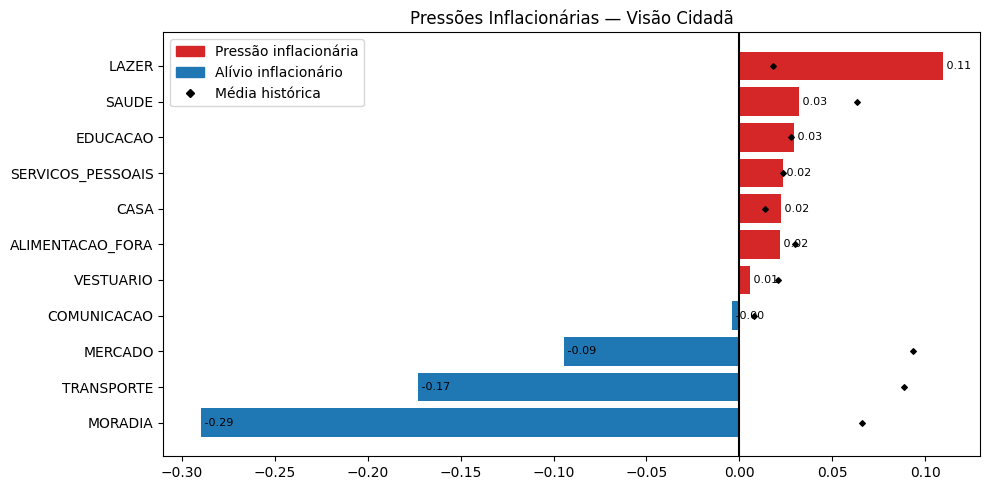

In [52]:
plt.figure(figsize=(10, 5))

cores = np.where(cidada_atual["contribuicao"] >= 0,
    "tab:red",
    "tab:blue",
)

plt.barh(
    cidada_atual["categoria_cidada"],
    cidada_atual["contribuicao"],
    color=cores,
)

# labels atuais
for _, row in cidada_atual.iterrows():

    plt.text(
        row["contribuicao"], row["categoria_cidada"],
        f" {row['contribuicao']:.2f}",
        va="center", fontsize=8,
    )

plt.axvline(0, color="black",)
plt.title("Pressões Inflacionárias — Visão Cidadã")

# média histórica
plt.scatter(
    cidada_atual["media"], cidada_atual["categoria_cidada"],
    color="black", marker="D", s=8,)


legenda = [
    Patch(color="tab:red", label="Pressão inflacionária",),
    Patch(color="tab:blue", label="Alívio inflacionário",),
    Line2D([0], [0],
        marker="D", color="black",
        linestyle="None", markersize=4, label="Média histórica",
    ),
]

plt.legend(handles=legenda,)
#    loc="lower right",

plt.tight_layout()
plt.show()

### 24. Heatmap Cidadão

In [35]:
heat_cidada = (
    cidada
    .pivot(
        index="date",
        columns="categoria_cidada",
        values="contribuicao",
    )
    .tail(24)
)

heat_cidada.index = (
    heat_cidada.index
    .strftime("%b-%y")
)

heat_cidada.tail()

categoria_cidada,ALIMENTACAO_FORA,CASA,COMUNICACAO,EDUCACAO,LAZER,MERCADO,MORADIA,SAUDE,SERVICOS_PESSOAIS,TRANSPORTE,VESTUARIO
date,,,,,,,,,,,
Apr-26,0.0357,0.0226,0.0259,0.0038,-0.0070,0.2524,0.0955,0.1582,0.0426,0.0121,0.0242
May-26,0.0297,0.0028,0.0103,-0.0001,0.0139,0.2570,0.1862,0.1226,0.0279,-0.0945,0.0288
Jun-26,0.0093,0.0080,0.0086,-0.0015,-0.0005,-0.0609,0.0967,0.0315,0.0262,0.0343,0.0078
Jul-26,0.0331,0.0024,0.0020,-0.0020,-0.0001,-0.1774,0.1512,0.0555,0.0222,0.0096,-0.0307
Aug-26,0.0219,0.0221,-0.0041,0.0292,0.1095,-0.0941,-0.2899,0.0323,0.0233,-0.1731,0.0055


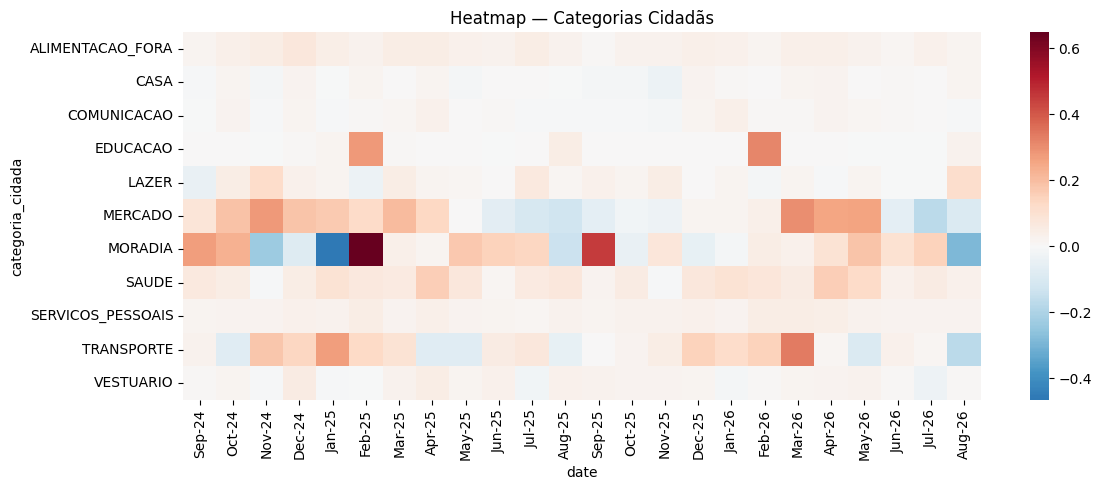

In [36]:
plt.figure(
    figsize=(12,5)
)

sns.heatmap(
    heat_cidada.T,
    cmap="RdBu_r",
    center=0,
)

plt.title(
    "Heatmap — Categorias Cidadãs"
)

plt.tight_layout()
plt.show()

### 25. O Que Está Pesando no Bolso?

O ranking cidadão permite organizar a inflação por temas
facilmente reconhecidos pelas famílias:

- Mercado
- Alimentação Fora
- Moradia
- Transporte
- Saúde
- Educação
- Comunicação
- Lazer
- Casa
- Vestuário
- Serviços Pessoais

Esta camada não substitui a análise econômica.

Ela traduz o IPCA para uma linguagem mais próxima da realidade
cotidiana das famílias.

---
## PARTE IV · COMPARAÇÃO
---

As duas taxonomias respondem perguntas diferentes:

Econômica:

- Serviços
- Monitorados
- Bens Industriais
- Alimentação

Cidadã:

- Mercado
- Moradia
- Transporte
- Saúde
- Educação

A combinação das duas permite interpretar a inflação
sob perspectivas complementares.

### 26. Taxonomia Econômica

In [37]:
pd.DataFrame(
    {
        "bloco_macro": sorted(
            dados["bloco_macro"]
            .dropna()
            .unique()
        )
    }
)

,bloco_macro
0,ALIMENTACAO_DOMICILIO
1,ALIMENTACAO_FORA
2,BENS_INDUSTRIAIS
3,MONITORADOS
4,SERVICOS


### 27. Taxonomia Cidadã

In [38]:
pd.DataFrame(
    {
        "categoria_cidada": sorted(
            dados["categoria_cidada"]
            .dropna()
            .unique()
        )
    }
)

,categoria_cidada
0,ALIMENTACAO_FORA
1,CASA
2,COMUNICACAO
3,EDUCACAO
4,LAZER
5,MERCADO
6,MORADIA
7,SAUDE
8,SERVICOS_PESSOAIS
9,TRANSPORTE


### 28. Participação Econômica Atual

In [39]:
macro_resumo = (
    blocos[
        blocos["date"]
        == ultimo_mes
    ]
    [
        [
            "bloco_macro",
            "contribuicao",
            "participacao",
        ]
    ]
    .sort_values(
        "participacao",
        ascending=False,
    )
)

macro_resumo

,bloco_macro,contribuicao,participacao
398,MONITORADOS,-0.3627,0.3345
395,ALIMENTACAO_DOMICILIO,-0.0941,0.2318
399,SERVICOS,-0.0104,0.2144
397,BENS_INDUSTRIAIS,0.1278,0.2015
396,ALIMENTACAO_FORA,0.0219,0.0178


In [40]:
macro_resumo.style.format(
    {
        "contribuicao": "{:.3f}",
        "participacao": "{:.1%}",
    }
)

,bloco_macro,contribuicao,participacao
398,MONITORADOS,-0.363,33.5%
395,ALIMENTACAO_DOMICILIO,-0.094,23.2%
399,SERVICOS,-0.010,21.4%
397,BENS_INDUSTRIAIS,0.128,20.1%
396,ALIMENTACAO_FORA,0.022,1.8%


### 29. Participação Cidadã Atual

In [41]:
cidada_resumo = (
    cidada[
        cidada["date"]
        == ultimo_mes_cidada
    ]
    [
        [
            "categoria_cidada",
            "contribuicao",
            "participacao",
        ]
    ]
    .sort_values(
        "participacao",
        ascending=False,
    )
)

cidada_resumo

,categoria_cidada,contribuicao,participacao
875,MORADIA,-0.2899,0.3061
874,MERCADO,-0.0941,0.2318
878,TRANSPORTE,-0.1731,0.1934
873,LAZER,0.1095,0.1078
876,SAUDE,0.0323,0.0482
872,EDUCACAO,0.0292,0.0288
870,CASA,0.0221,0.0220
879,VESTUARIO,0.0055,0.0206
877,SERVICOS_PESSOAIS,0.0233,0.0200
869,ALIMENTACAO_FORA,0.0219,0.0178


In [42]:
cidada_resumo.style.format(
    {
        "contribuicao": "{:.3f}",
        "participacao": "{:.1%}",
    }
)

,categoria_cidada,contribuicao,participacao
875,MORADIA,-0.290,30.6%
874,MERCADO,-0.094,23.2%
878,TRANSPORTE,-0.173,19.3%
873,LAZER,0.109,10.8%
876,SAUDE,0.032,4.8%
872,EDUCACAO,0.029,2.9%
870,CASA,0.022,2.2%
879,VESTUARIO,0.006,2.1%
877,SERVICOS_PESSOAIS,0.023,2.0%
869,ALIMENTACAO_FORA,0.022,1.8%


### 30. Comparação das Leituras

Leitura Econômica:

- identifica mecanismos inflacionários;
- aproxima o projeto da linguagem do Banco Central;
- facilita modelagem econômica;
- permite integrar inflação e política monetária.

Leitura Cidadã:

- traduz a inflação para o cotidiano;
- facilita comunicação pública;
- aproxima o indicador das famílias;
- permite monitorar pressões específicas.

---
## PARTE V · PAINEL EXECUTIVO
---

### 31. Principais Indicadores

In [43]:
painel = pd.DataFrame(
    [
        {
            "indicador": "IPCA Reconstruído",
            "valor": (
                reconstrucao["ipca_blocos"]
                .iloc[-1]
            ),
        },
        {
            "indicador": "Erro de Reconstrução",
            "valor": (
                validacao["erro_abs"]
                .iloc[-1]
            ),
        },
        {
            "indicador": "Blocos Macro",
            "valor": (
                dados["bloco_macro"]
                .nunique()
            ),
        },
        {
            "indicador": "Categorias Cidadãs",
            "valor": (
                dados["categoria_cidada"]
                .nunique()
            ),
        },
    ]
)

painel

,indicador,valor
0,IPCA Reconstruído,-0.3176
1,Erro de Reconstrução,0.0024
2,Blocos Macro,5.0000
3,Categorias Cidadãs,11.0000


### 32. Dominância Econômica

In [44]:
macro_atual.head(3)

,date,bloco_macro,contribuicao,impacto,impacto_total,participacao
397,2026-08-01,BENS_INDUSTRIAIS,0.1278,0.2471,1.2264,0.2015
396,2026-08-01,ALIMENTACAO_FORA,0.0219,0.0219,1.2264,0.0178
399,2026-08-01,SERVICOS,-0.0104,0.2630,1.2264,0.2144


### 33. Dominância Cidadã

In [45]:
cidada_atual.sort_values(
    "contribuicao",
    ascending=False,
).head(3)

,date,categoria_cidada,contribuicao,impacto,impacto_total,participacao,media,desvio
0,2026-08-01,LAZER,0.1095,0.1322,1.2264,0.1078,0.0181,0.0913
1,2026-08-01,SAUDE,0.0323,0.0591,1.2264,0.0482,0.0631,-0.0308
2,2026-08-01,EDUCACAO,0.0292,0.0354,1.2264,0.0288,0.0276,0.0016


### 34. Narrativa Econômica

Sequência sugerida de leitura:

1. Qual foi o IPCA?

2. Qual bloco econômico respondeu pela maior parcela?

3. Qual bloco ajudou a conter a inflação?

4. Houve mudança estrutural recente?

5. Como os monitorados se comportaram?

6. Os serviços permanecem pressionando?

7. Alimentação continua liderando?

### 35. Narrativa Cidadã

Sequência sugerida:

1. O mercado pressionou?

2. Moradia está mais cara?

3. Transporte ajudou ou prejudicou?

4. Saúde elevou o índice?

5. Educação continua pressionando?

6. Quais categorias estão acima da média histórica?

---
## PARTE VI · CONCLUSÕES
---

### 36. Conclusões

Este notebook introduziu uma camada de interpretação econômica para o IPCA.

A taxonomia econômica permitiu organizar os subitens em:

- ALIMENTACAO_DOMICILIO
- ALIMENTACAO_FORA
- BENS_INDUSTRIAIS
- SERVICOS
- MONITORADOS

A taxonomia cidadã permitiu organizar a inflação em:

- MERCADO
- ALIMENTACAO_FORA
- MORADIA
- TRANSPORTE
- SAUDE
- EDUCACAO
- COMUNICACAO
- LAZER
- CASA
- VESTUARIO
- SERVICOS_PESSOAIS

A combinação das duas leituras aproxima o IPCA
simultaneamente:

- da literatura econômica;
- do Banco Central;
- da modelagem futura;
- da realidade das famílias.

O notebook respondeu:

> De onde economicamente está vindo a inflação?

e também:

> O que está pressionando o orçamento dos brasileiros?

### Principais Resultados

Taxonomia:

✅ Cobertura total dos subitens

✅ Reconstrução do IPCA pelos blocos

✅ Blocos macroeconômicos

✅ Visão cidadã

✅ Heatmap econômico

✅ Heatmap cidadão

✅ Ranking econômico

✅ Ranking cidadão

### Próxima Etapa

O próximo notebook será:

06.ipca_politica_monetaria

A pergunta muda de:

> De onde vem a inflação?

para:

> Como a política monetária interage com a inflação?

Entraremos então em:

- SELIC
- correlação temporal
- defasagens
- transmissão monetária
- preparação para feature engineering

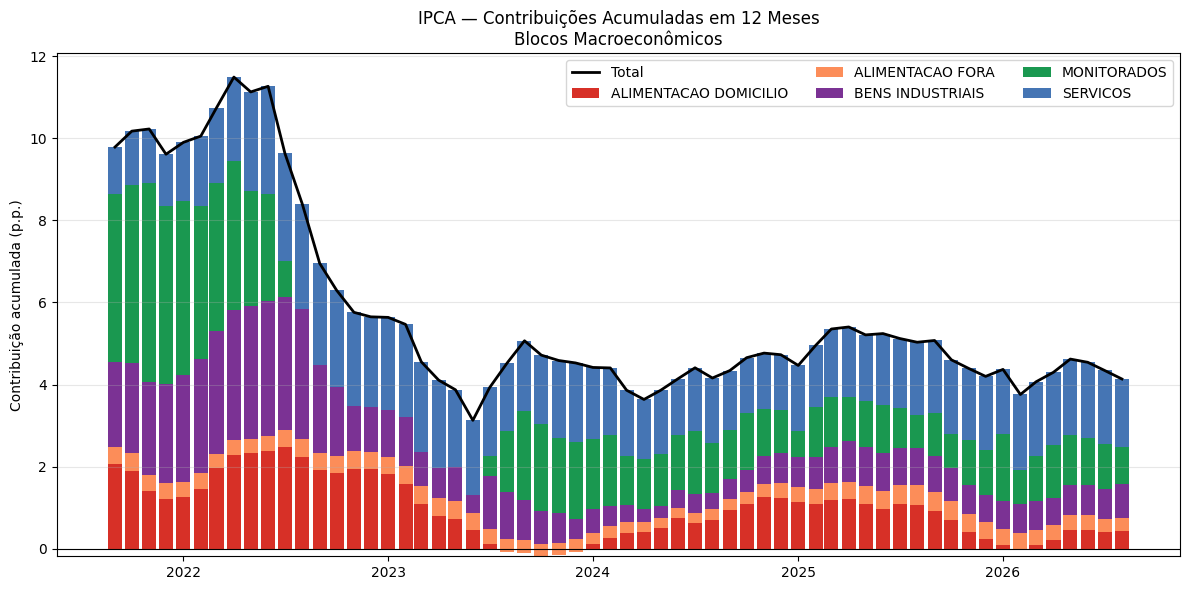

In [53]:
fig, ax = plt.subplots(figsize=(12, 6))
bottom = np.zeros(len(blocos_12m.tail(60)))

cores = {
    "ALIMENTACAO_DOMICILIO": "#d73027",
    "ALIMENTACAO_FORA": "#fc8d59",
    "SERVICOS": "#4575b4",
    "MONITORADOS": "#1a9850",
    "BENS_INDUSTRIAIS": "#7b3294",
}

dados_plot = (blocos_12m.tail(60))

for col in dados_plot.columns:
    ax.bar(
        dados_plot.index,
        dados_plot[col],
        bottom=bottom,
        label=col.replace("_", " "),
        color=cores.get(col),
        width=25,
    )

    bottom += (dados_plot[col].fillna(0).values)

# total acumulado

ax.plot(
    dados_plot.index,
    bottom,
    color="black",
    linewidth=2,
    label="Total",
)

ax.axhline(0, color="black", linewidth=0.8,)
ax.set_title("IPCA — Contribuições Acumuladas em 12 Meses\nBlocos Macroeconômicos")
ax.set_ylabel("Contribuição acumulada (p.p.)")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.3,)
ax.legend(ncols=3, frameon=True,)

plt.tight_layout()
plt.show()

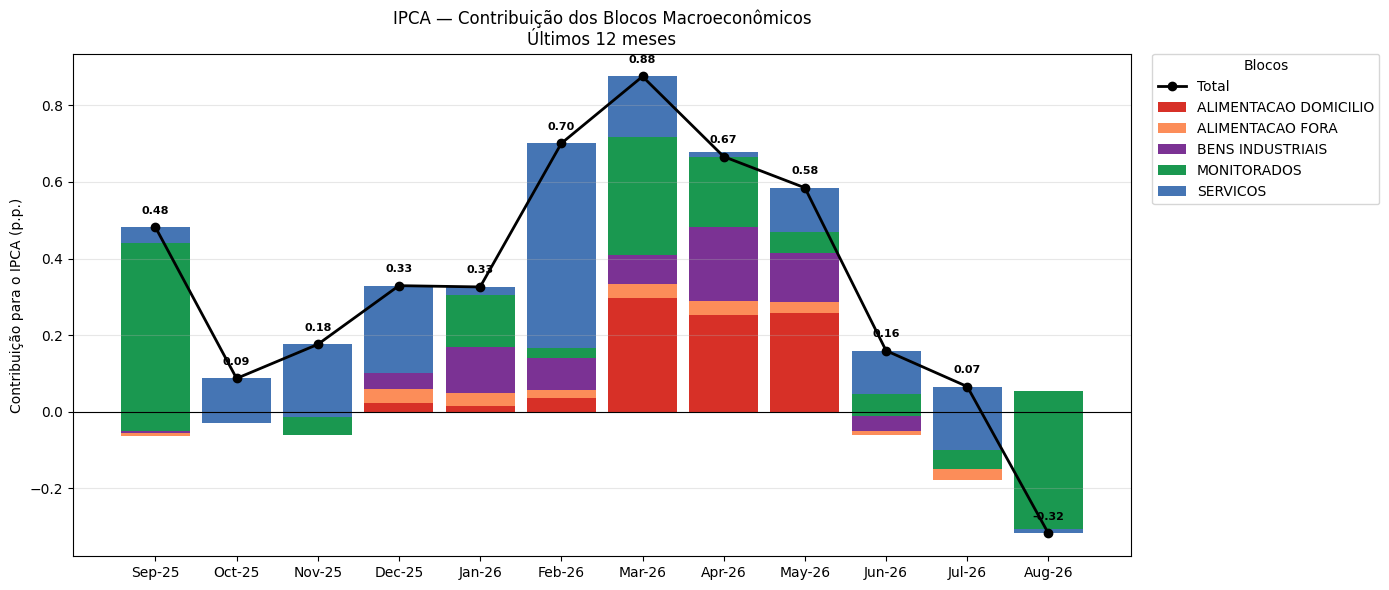

In [54]:
# ============================================================
# CONTRIBUIÇÃO DOS BLOCOS
# ÚLTIMOS 12 MESES
# ============================================================

m = 12

df_blocos_m = (
    blocos_pivot
    .tail(m)
    .copy()
)

df_blocos_m.index = (
    df_blocos_m.index
    .strftime("%b-%y")
)

df_blocos_m["Total"] = (
    df_blocos_m.sum(axis=1)
)

cores = {
    "ALIMENTACAO_DOMICILIO": "#d73027",
    "ALIMENTACAO_FORA": "#fc8d59",
    "SERVICOS": "#4575b4",
    "MONITORADOS": "#1a9850",
    "BENS_INDUSTRIAIS": "#7b3294",
}

plt.figure(figsize=(14, 6))

ax = plt.gca()

bottom = np.zeros(
    len(df_blocos_m)
)

for col in (
    df_blocos_m
    .drop(columns="Total")
    .columns
):

    ax.bar(
        df_blocos_m.index,
        df_blocos_m[col],
        bottom=bottom,
        width=0.85,
        color=cores.get(col),
        label=col.replace("_", " "),
    )

    bottom += (
        df_blocos_m[col]
        .fillna(0)
        .values
    )

# --------------------------------------------------
# TOTAL DO IPCA RECONSTRUÍDO
# --------------------------------------------------

ax.plot(
    df_blocos_m.index,
    df_blocos_m["Total"],
    color="black",
    linewidth=2,
    marker="o",
    label="Total",
)

# --------------------------------------------------
# RÓTULO DOS TOTAIS
# --------------------------------------------------

for i, total in enumerate(
    df_blocos_m["Total"]
):

    ax.text(
        i,
        total + 0.03,
        f"{total:.2f}",
        ha="center",
        va="bottom",
        fontsize=8,
        fontweight="bold",
    )

# --------------------------------------------------
# FORMATAÇÃO
# --------------------------------------------------

plt.axhline(
    0,
    color="black",
    linewidth=0.8,
)

plt.title(
    (
        "IPCA — Contribuição dos Blocos Macroeconômicos\n"
        f"Últimos {m} meses"
    )
)

plt.ylabel(
    "Contribuição para o IPCA (p.p.)"
)

plt.xlabel("")

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.legend(
    title="Blocos",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0,
)

plt.tight_layout()

plt.show()